# 3.2 — Data Preparation

**Goal:** Telco Customer Churn dataset-কে Machine Learning-এর জন্য প্রস্তুত করা।

এই অংশে data download/read করব, column ও text value uniform করব, `totalcharges` ঠিক করব এবং target `churn`-কে numeric বানাব।

## 1. প্রয়োজনীয় libraries import করা

**কেন?** `pandas` দিয়ে dataset handle করব, `numpy` numerical কাজের জন্য এবং `matplotlib` পরের analysis/visualization-এর কাজে লাগবে।

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Dataset download করা



In [14]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

# !wget $data -O data-week-3.csv

## 3. CSV পড়া ও data দেখা


In [15]:
df = pd.read_csv('data-week-3.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'data-week-3.csv'

`df.head()`-এ অনেক column থাকলে মাঝের column-গুলো `...` দিয়ে লুকানো থাকতে পারে। Transpose করলে row ও column-এর অবস্থান বদলে যায়, তাই সব column-এর value একসঙ্গে দেখা সহজ হয়।

In [ ]:
df.shape

(7043, 21)

In [ ]:
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


## 4. Column name ও text value uniform করা


In [ ]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

## 5. Data type পরীক্ষা করা

**কেন?** কোনো column-এর value দেখতে number-এর মতো হলেও pandas সেটিকে string হিসেবে পড়েছে কি না, তা বুঝতে চাই। বিশেষ করে `totalcharges` numeric হওয়া উচিত।

In [ ]:
df.dtypes

customerid           object
gender               object
seniorcitizen         int64
partner              object
dependents           object
tenure                int64
phoneservice         object
multiplelines        object
internetservice      object
onlinesecurity       object
onlinebackup         object
deviceprotection     object
techsupport          object
streamingtv          object
streamingmovies      object
contract             object
paperlessbilling     object
paymentmethod        object
monthlycharges      float64
totalcharges         object
churn                object
dtype: object

## 6. `totalcharges`-কে numeric-এ রূপান্তর

Original data-তে কিছু missing value ফাঁকা space দিয়ে লেখা ছিল। আগের step-এ space `_` হয়ে যাওয়ায় `totalcharges`-এ কিছু value `_` হয়েছে; pandas এটিকে number হিসেবে convert করতে পারে না।

In [ ]:
df['totalcharges']
# shob to number ei dekha jacche tai na? then numeric e convert kore dekhi tahole ei column ke object boltese ken

0         29.85
1        1889.5
2        108.15
3       1840.75
4        151.65
         ...   
7038     1990.5
7039     7362.9
7040     346.45
7041      306.6
7042     6844.5
Name: totalcharges, Length: 7043, dtype: object

In [ ]:
# pd.to_numeric(df['totalcharges'])

In [ ]:
# so uporer error dekhay: ValueError: Unable to parse string "_" at position 488
# mane 488 index e "_" ache, tai numeric e convert korte parlo na. so ei row ta dekhbo. maybe aaro emon ase. but error er first index tai show kore.

df['totalcharges'].iloc[488]

'_'

In [ ]:
pd.to_numeric(df['totalcharges'], errors='coerce')

# now error gone.

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: totalcharges, Length: 7043, dtype: float64

`errors='coerce'` invalid value-কে `NaN` বানায়, ফলে conversion error দিয়ে থেমে যায় না। এরপর কতগুলো missing value হয়েছে, তা গুনি।

In [ ]:
tc = pd.to_numeric(df['totalcharges'], errors='coerce')

In [ ]:
tc.isnull().sum()

np.int64(11)

## 7. Missing row দেখা ও ঠিক করা

**কেন?** কোন customer-দের `totalcharges` missing, তা পরীক্ষা করে তারপর উপযুক্ত value বসাব।

In [ ]:
# 11 ta row te null value ase. oi 11 ta row dekhbo.

df[tc.isnull()]

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
488,4472-lvygi,female,0,yes,yes,0,no,no_phone_service,dsl,yes,...,yes,yes,yes,no,two_year,yes,bank_transfer_(automatic),52.55,_,no
753,3115-czmzd,male,0,no,yes,0,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,20.25,_,no
936,5709-lvoeq,female,0,yes,yes,0,yes,no,dsl,yes,...,yes,no,yes,yes,two_year,no,mailed_check,80.85,_,no
1082,4367-nuyao,male,0,yes,yes,0,yes,yes,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,25.75,_,no
1340,1371-dwpaz,female,0,yes,yes,0,no,no_phone_service,dsl,yes,...,yes,yes,yes,no,two_year,no,credit_card_(automatic),56.05,_,no
3331,7644-omvmy,male,0,yes,yes,0,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.85,_,no
3826,3213-vvolg,male,0,yes,yes,0,yes,yes,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,25.35,_,no
4380,2520-sgtta,female,0,yes,yes,0,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,20.00,_,no
5218,2923-arzlg,male,0,yes,yes,0,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,one_year,yes,mailed_check,19.70,_,no
6670,4075-wkniu,female,0,yes,yes,0,yes,yes,dsl,no,...,yes,yes,yes,no,two_year,no,mailed_check,73.35,_,no


In [ ]:
df[tc.isnull()][['customerid', 'totalcharges']]

,customerid,totalcharges
488,4472-lvygi,_
753,3115-czmzd,_
936,5709-lvoeq,_
1082,4367-nuyao,_
1340,1371-dwpaz,_
3331,7644-omvmy,_
3826,3213-vvolg,_
4380,2520-sgtta,_
5218,2923-arzlg,_
6670,4075-wkniu,_


এই dataset-এ এমন ১১টি row আছে। এগুলো সাধারণত নতুন customer, যাদের total charge রেকর্ড হয়নি। তাই এখানে missing `totalcharges`-কে `0` দিয়ে পূরণ করছি। অন্য dataset-এ সবসময় `0` উপযুক্ত নাও হতে পারে।

In [ ]:
df['totalcharges'] = pd.to_numeric(df['totalcharges'], errors='coerce').fillna(0)

## 8. Target variable `churn` numeric করা

**কেন?** `churn`-এ `yes`/`no` string আছে। Classification model-এর জন্য এটিকে `1`/`0` করা দরকার।

- `yes` → `1`: customer churn করেছে।
- `no` → `0`: customer churn করেনি।

In [ ]:
df.churn.head()

0     no
1     no
2    yes
3     no
4    yes
Name: churn, dtype: object

In [ ]:
df['churn'] = (df['churn'] == 'yes').astype(int)
df['churn'].head()

0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

In [ ]:
df.dtypes

customerid           object
gender               object
seniorcitizen         int64
partner              object
dependents           object
tenure                int64
phoneservice         object
multiplelines        object
internetservice      object
onlinesecurity       object
onlinebackup         object
deviceprotection     object
techsupport          object
streamingtv          object
streamingmovies      object
contract             object
paperlessbilling     object
paymentmethod        object
monthlycharges      float64
totalcharges        float64
churn                 int64
dtype: object

# 3.3 — Setting Up the Validation Framework

## 1. `train_test_split` import করা

**কেন?** Scikit-Learn-এর `train_test_split()` দিয়ে dataset-কে randomভাবে দুই ভাগে ভাগ করা যায়। একবারে তিন ভাগ হয় না, তাই দুই ধাপে split করব।

In [ ]:
from sklearn.model_selection import train_test_split

## 2. Dataset-কে 60% / 20% / 20% ভাগ করা

প্রথমে 20% `test` set আলাদা করি। বাকি 80% থাকবে `df_full_train`-এ।

- `test_size=0.2` → মোট data-এর 20% test set-এ যায়।
- `random_state=1` → একই seed থাকলে প্রতিবার একই split পাওয়া যায়।

In [ ]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

এখন বাকি 80% থেকে `train` ও `validation` set বানাই।

**কেন `test_size=0.25`?** এই ধাপের input হলো মূল dataset-এর 80%। তার 25% হলো মূল dataset-এর 20% — তাই validation set মোট data-এর 20% হবে।

In [ ]:
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

## 3. Split-এর size পরীক্ষা করা

Expected output: `(4225, 1409, 1409)`

- `df_train`: 4,225 rows (প্রায় 60%)
- `df_val`: 1,409 rows (প্রায় 20%)
- `df_test`: 1,409 rows (প্রায় 20%)

In [ ]:
len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

## 4. Index reset করা

`train_test_split()` row shuffle করে, তাই পুরোনো index এলোমেলো থাকতে পারে। eta model e provab fele na. tai eta optional

In [ ]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

df_full_train = df_full_train.reset_index(drop=True)

## 5. Target `churn` আলাদা করা

In [ ]:
y_train = df_train.churn.to_numpy()
y_val = df_val.churn.to_numpy()
y_test = df_test.churn.to_numpy()

এরপর তিনটি dataframe থেকে `churn` column মুছে ফেলি।

**কেন?** `churn`-কে input feature হিসেবে রেখে দিলে model উত্তরটি আগেই পেয়ে যেতে পারে — একে **target leakage** বলে।

In [ ]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

**মনে রাখবে:** `df_full_train`-এ `churn` রাখা হয়েছে, কারণ পরের EDA ধাপে target-এর distribution ও churn rate বিশ্লেষণ করতে হবে। EDA শুরু করার সময় এর index-ও reset করা হবে।

# 3.4 — EDA (Exploratory Data Analysis)

এখানে `df_full_train` ব্যবহার করছি (train + validation data)। `df_test` শেষ evaluation-এর আগে আলাদা রাখব।

## 1. Missing values check করা

In [ ]:
df_full_train.isnull().sum()

# kono column ei r missing value nai. karon amra agei resolve korsi.

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

## 3. Churn rate বোঝা

`churn` হলো target column:

- `0` = customer থেকে গেছে
- `1` = customer চলে গেছে (churn করেছে)



### 3.1 প্রতিটি value-এর proportion দেখা

`normalize=True` দিলে `value_counts()` শুধু count না দিয়ে total rows-এর অনুপাতে fraction দেখায়।

উদাহরণস্বরূপ result:

- `0 → 0.730` অর্থ প্রায় **73% customer থেকে গেছে**।
- `1 → 0.270` অর্থ প্রায় **27% customer churn করেছে**।

এই `1`-এর proportion-টাই **churn rate**। Percentage-এ পেতে `0.270 × 100 ≈ 27%`।

In [ ]:
df_full_train['churn'].value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

### 3.2 `churn.mean()` কেন churn rate দেয়?

`churn` column-এ শুধু `0` ও `1` আছে। Mean = সব value-এর যোগফল ÷ মোট value-এর সংখ্যা। `0` যোগফলে কিছু যোগ করে না; প্রতিটি `1` এক যোগ করে। তাই:

$$
\text{mean} = \frac{\text{number of 1s}}{\text{total rows}} = \text{churn rate}
$$

**সহজ উদাহরণ:** `[0, 0, 1, 0, 1]`—৫ জনের মধ্যে ২ জন churn করেছে। Mean = `(0+0+1+0+1) / 5 = 2/5 = 0.4`, অর্থাৎ churn rate **40%**।

In [ ]:
df_full_train['churn'].mean()

np.float64(0.26996805111821087)

এই dataset-এ result প্রায় `0.270`, অর্থাৎ churn rate প্রায় **27%**। তাই binary (0/1) column-এর mean দিয়ে 1-এর proportion বের করা যায়।

## 4. Numerical ও categorical columns আলাদা করা

In [ ]:
df_full_train.columns

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='object')

### Numerical columns

- `tenure`: customer কত মাস ধরে আছে
- `monthlycharges`: প্রতি মাসের charge
- `totalcharges`: মোট charge

`seniorcitizen` দেখতে `0/1` হলেও এটি আসলে category (senior citizen কি না)। `churn` হলো target, আর `customerid` শুধু identifier—সাধারণ feature হিসেবে ব্যবহার করব না।

In [ ]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

### Categorical columns

In [ ]:
categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

# 3.5 — Feature Importance: Churn Rate & Risk Ratio

**Goal:** কোন categorical feature-এর কোন group-এ customer churn বেশি বা কম, তা global churn rate-এর সঙ্গে তুলনা করা।

এই notebook-এ 3.3–3.4 থেকে পাওয়া `df_full_train` এবং `categorical` list ব্যবহার করা হয়েছে। `churn` আগে থেকেই `0` (থেকে গেছে) ও `1` (চলে গেছে) হিসেবে encoded থাকতে হবে।

## 1. Global churn rate বের করা

```python
global_churn = df_full_train.churn.mean()
```

**কেন?** এটি পুরো `df_full_train` dataset-এর average churn rate; প্রতিটি group-এর সঙ্গে তুলনা করার reference point। `churn`-এ 1 মানে churn করেছে এবং 0 মানে করেনি, তাই mean-ই churn করা customer-দের proportion।

In [ ]:
global_churn = df_full_train.churn.mean()
global_churn

np.float64(0.26996805111821087)

প্রত্যাশিত ফল প্রায় **0.27 = 27%**। অর্থাৎ পুরো dataset-এ প্রতি 100 জন customer-এর মধ্যে প্রায় 27 জন churn করেছে।

## 2. একটি feature দিয়ে শুরু: `partner`

আগে loop ব্যবহার না করে শুধু `partner` column দেখি। এখানে দুইটি group: `yes` এবং `no`।

### 2.1 প্রতিটি group-এ কতজন customer আছে?

In [ ]:
df_full_train.partner.value_counts()

partner
no     2932
yes    2702
Name: count, dtype: int64

এতে প্রতিটি category-র customer count পাওয়া যায়। Count জানা থাকলে rate কতজন customer-এর ওপর ভিত্তি করে এসেছে, সেটাও বোঝা যায়।

### 2.2 Group অনুযায়ী churn rate বের করা

**কেন?** প্রথমে `partner == 'yes'` দিয়ে সেই group-এর rows filter করি; তারপর তাদের `churn.mean()` হিসাব করি। একইভাবে `partner == 'no'` group-এর rate বের করি।

In [ ]:
churn_partner = df_full_train[df_full_train.partner == 'yes'].churn.mean()
churn_no_partner = df_full_train[df_full_train.partner == 'no'].churn.mean()

churn_partner, churn_no_partner

(np.float64(0.20503330866025166), np.float64(0.3298090040927694))

ফল প্রায়:

- `partner = yes` → **20.5%** churn
- `partner = no` → **33.0%** churn
- Global churn rate → **27.0%**

অর্থাৎ partner নেই এমন customer-দের churn rate global average-এর চেয়ে বেশি; partner আছে এমন customer-দের rate কম।

### 2.3 Difference দিয়ে global rate-এর সঙ্গে তুলনা

এখানে একটাই formula ব্যবহার করব:

$$\text{diff} = \text{group churn rate} - \text{global churn rate}$$

এই convention সহজে interpret করা যায়:

- `diff > 0` → group-এর churn rate global average-এর **চেয়ে বেশি**।
- `diff < 0` → group-এর churn rate global average-এর **চেয়ে কম**।
- `diff = 0` → group ও global churn rate সমান।

Difference-এর absolute value যত বড়, group-এর rate global average থেকে তত বেশি দূরে।

In [ ]:
diff_partner = churn_partner - global_churn
diff_no_partner = churn_no_partner - global_churn

diff_partner, diff_no_partner

(np.float64(-0.06493474245795922), np.float64(0.05984095297455855))

- `partner=yes`: `0.2050 - 0.2700 ≈ -0.0649` → global average-এর চেয়ে প্রায় **6.5 percentage points কম** churn।
- `partner=no`: `0.3298 - 0.2700 ≈ +0.0598` → global average-এর চেয়ে প্রায় **6.0 percentage points বেশি** churn।

এখানে `diff`-এর sign সরাসরি direction জানায়: **positive = বেশি churn, negative = কম churn**।

### 2.4 Risk ratio দিয়ে তুলনা

Difference absolute gap দেখায়। Risk ratio দেখায় group-এর churn rate global rate-এর তুলনায় কত গুণ।

$$
\text{risk ratio} = \frac{\text{group churn rate}}{\text{global churn rate}}
$$

মনে রাখো:

- `risk = 1` → global average-এর সমান
- `risk > 1` → global average-এর চেয়ে বেশি churn
- `risk < 1` → global average-এর চেয়ে কম churn

In [ ]:
risk_no_partner = churn_no_partner / global_churn
risk_partner = churn_partner / global_churn

risk_no_partner, risk_partner

(np.float64(1.2216593879412643), np.float64(0.7594724924338315))

ফল প্রায়:

- `partner=no` → **1.22**: global average-এর তুলনায় প্রায় **22% বেশি** churn।
- `partner=yes` → **0.76**: global average-এর তুলনায় প্রায় **24% কম** churn।

যেমন `1.22` মানে 122% churn rate নয়; এটি global rate-এর **1.22 গুণ** বোঝায়।

## 3. SQL `GROUP BY` দিয়ে একই calculation

একটি feature-এর category অনুযায়ী group করে churn rate, difference ও risk ratio বের করার একই idea SQL দিয়েও লেখা যায়।

### SQL code

```sql
SELECT
    gender,
    AVG(churn),
    AVG(churn) - global_churn AS diff,
    AVG(churn) / global_churn AS risk
FROM
    data
GROUP BY
    gender;
```

**কেন প্রতিটি line লিখেছি?**

- `SELECT gender` — gender অনুযায়ী result চাই।
- `AVG(churn)` — প্রতিটি gender group-এর churn rate; কারণ `churn` শুধু `0` বা `1`, তাই average-ই churn করা customer-এর proportion।
- `AVG(churn) - global_churn AS diff` — **group rate − global rate**। Positive হলে group-এর churn বেশি, negative হলে কম।
- `AVG(churn) / global_churn AS risk` — group rate global rate-এর কত গুণ, তা বের করে।
- `FROM data` — source table নির্ধারণ করে।
- `GROUP BY gender` — একই gender-এর row এক group-এ এনে আলাদা হিসাব করে।

**নোট:** এই উদাহরণে `global_churn`-কে আগে থেকে হিসাব করা scalar value ধরা হয়েছে। বাস্তব SQL query-তে সেটি database অনুযায়ী variable, CTE বা subquery দিয়ে define করতে হবে।

## 4. Pandas `groupby()` দিয়ে `partner`-এর table

SQL-এর মতোই Pandas-এ `groupby()` category অনুযায়ী group তৈরি করে। প্রথমে শুধু `partner` দিয়ে হিসাব করি, তারপর `diff` ও `risk` যোগ করি।

In [ ]:
df_group = df_full_train.groupby('partner').churn.agg(['mean', 'count'])
df_group

,mean,count
partner,,
no,0.329809,2932
yes,0.205033,2702


- `groupby('partner')` → `yes` ও `no` group তৈরি করে।
- `mean` → প্রতিটি group-এর churn rate।
- `count` → প্রতিটি group-এ customer সংখ্যা।

এখন table-এ difference ও risk ratio যোগ করব। উপরের manual calculation-এর মতোই এখানে `diff = group mean - global churn` ব্যবহার করব, তাই positive/negative sign-এর অর্থ সব জায়গায় একই থাকবে।

In [ ]:
df_group['diff'] = df_group['mean'] - global_churn
df_group['risk'] = df_group['mean'] / global_churn
df_group

,mean,count,diff,risk
partner,,,,
no,0.329809,2932,0.059841,1.221659
yes,0.205033,2702,-0.064935,0.759472


এই table-এ একই interpretation প্রযোজ্য:

- `diff > 0` → group global average-এর চেয়ে **বেশি** churn করে।
- `diff < 0` → group global average-এর চেয়ে **কম** churn করে।
- `risk > 1` → group-এর churn rate global average-এর চেয়ে বেশি।
- `risk < 1` → group-এর churn rate global average-এর চেয়ে কম।

ফলে `partner=no`-এর `diff` প্রায় `+0.0598`, আর `partner=yes`-এর `diff` প্রায় `-0.0649`।

## 5. Loop দিয়ে সব categorical feature বিশ্লেষণ

একটি column-এর `groupby()` table বোঝার পর একই হিসাব সব categorical column-এর জন্য চালাই। এখানে `diff` formula আগের মতোই `group mean - global churn` থাকবে।

In [ ]:
from IPython.display import display

for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn
    df_group['risk'] = df_group['mean'] / global_churn
    display(df_group)
    print()

gender


,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980



seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208



partner


...

,mean,count,diff,risk
contract,,,,
month-to-month,0.431701,3104,0.161733,1.599082
one_year,0.120573,1186,-0.149395,0.446621
two_year,0.028274,1344,-0.241694,0.104730



paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560



paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121




`display()` ব্যবহার করা হয়েছে, কারণ loop-এর ভেতরে DataFrame শুধু লিখলে প্রতিটি table সুন্দরভাবে display নাও হতে পারে।

# 3.6 — Feature Importance: Mutual Information

**Goal:** কোন categorical feature থেকে `churn` সম্পর্কে কতটা তথ্য পাওয়া যায়, তা একটি score দিয়ে মাপা এবং সব feature-কে বেশি থেকে কম গুরুত্বপূর্ণ ক্রমে সাজানো।

**Prerequisite:** আগের notebook-এর `df_full_train` এবং `categorical` list তৈরি করা থাকতে হবে।

## Mutual Information (MI)

**Mutual Information (MI)** measures how much information one variable provides about another variable.

আমাদের project-এ আমরা জানতে চাই: কোনো customer-এর একটি feature জানলে তার `churn` সম্পর্কে কতটা ধারণা পাওয়া যায়?

### 1. Understanding Entropy

**Entropy** means uncertainty.

- `H(Y)` = `churn` সম্পর্কে uncertainty, কোনো feature না জেনে।
- `H(Y | X)` = feature `X` জানার পরেও `churn` সম্পর্কে যতটুকু uncertainty থাকে।
- `I(X; Y)` = feature `X` জানার কারণে `churn` সম্পর্কে যতটুকু uncertainty কমে।

এখানে:
- `X` = কোনো feature, যেমন `contract`
- `Y` = target variable, অর্থাৎ `churn`

### 2. Mutual Information Formula

$$
I(X;Y) = H(Y) - H(Y|X)
$$

সহজভাবে:

**Mutual Information = আগের uncertainty − feature জানার পরের uncertainty**

### 3. সহজ উদাহরণ

ধরো, কোনো customer-এর contract type জানার আগে আমরা শুধু জানি যে dataset-এ overall churn rate প্রায় 27%।

এখন contract type জানার পর দেখা গেল:
- `month-to-month` → churn rate প্রায় 43%
- `one_year` → churn rate প্রায় 12%
- `two_year` → churn rate প্রায় 3%

Contract type জানার পর customer-এর churn সম্পর্কে আমাদের ধারণা অনেক বেশি নির্দিষ্ট হলো। তাই `contract`-এর Mutual Information বেশি।

অন্যদিকে, নারী ও পুরুষ customer-এর churn rate প্রায় একই। Gender জানলে churn সম্পর্কে ধারণা খুব সামান্য বদলায়। তাই `gender`-এর Mutual Information প্রায় শূন্য।

### 4. MI Score কীভাবে বুঝবে?

- **High MI** → feature জানলে target সম্পর্কে অনেক information পাওয়া যায়।
- **Low MI** → feature জানলে target সম্পর্কে খুব কম information পাওয়া যায়।
- **MI = 0** → feature ও target-এর মধ্যে কোনো statistical information/association নেই।

**মনে রাখবে:** MI score বেশি মানেই feature সরাসরি churn ঘটায়—এমন নয়। এটি feature ও target-এর মধ্যে information-এর পরিমাণ বোঝায়।

## 2. Risk Ratio থেকে পার্থক্য

আগের অংশে `risk ratio` দিয়ে একটি feature-এর category-গুলোর churn rate global churn rate-এর সঙ্গে তুলনা করেছি। Mutual Information আলাদা: এটি **প্রতিটি categorical feature-এর জন্য একটি score** দেয়, তাই feature-গুলোকে একই scale-এ rank করা যায়।

উদাহরণ হিসেবে, এই dataset-এ `contract`-এর MI প্রায় `0.0983`, কিন্তু `gender`-এর MI প্রায় `0.0001`। তাই `contract` churn সম্পর্কে অনেক বেশি তথ্য দেয়; `gender` খুব কম দেয়।

## 3. Scikit-learn function import

In [ ]:
from sklearn.metrics import mutual_info_score

`mutual_info_score(x, y)` দুইটি categorical variable-এর mutual information score বের করে। আমাদের ক্ষেত্রে একটি variable হলো feature এবং অন্যটি হলো `df_full_train.churn`। Argument-এর order বদলালেও score একই থাকে, কারণ MI symmetric।

## 4. সব categorical feature-এর MI বের করা

একেকটি column-এর জন্য আলাদা করে code না লিখে, একটি function তৈরি করে `apply()` দিয়ে সব categorical column-এ চালাব।

In [ ]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

**Function-এর কাজ:**

- `series` হলো একবারে একটি categorical column, যেমন `contract` বা `gender`।
- `mutual_info_score(series, df_full_train.churn)` ওই column-এর সঙ্গে `churn`-এর MI score বের করে।
- function শুধু score return করে, যাতে `apply()` প্রতিটি column-এর জন্য একই calculation চালাতে পারে।

In [ ]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

### Code-টি কীভাবে কাজ করে?

1. `df_full_train[categorical]` → শুধু categorical feature-গুলোর column নেয়; target `churn`-কে feature list-এ রাখা হয়নি।
2. `.apply(mutual_info_churn_score)` → প্রতিটি column-এর ওপর function চালিয়ে একটি MI score বের করে।
3. `mi` → feature name-কে index এবং MI score-কে value হিসেবে রাখে।
4. `.sort_values(ascending=False)` → score বড় থেকে ছোট সাজায়, তাই উপরের feature-গুলো churn সম্পর্কে বেশি তথ্য দেয়।

## 5. এই dataset-এর result কীভাবে পড়বে?

| Feature | MI score (প্রায়) | Interpretation |
|---|---:|---|
| `contract` | 0.098320 | সবচেয়ে বেশি তথ্য দেয় |
| `onlinesecurity` | 0.063085 | গুরুত্বপূর্ণ signal |
| `techsupport` | 0.061032 | গুরুত্বপূর্ণ signal |
| `internetservice` | 0.055868 | গুরুত্বপূর্ণ signal |
| `paymentmethod` | 0.043210 | কিছু তথ্য দেয় |
| `partner` | 0.009968 | তুলনামূলক কম তথ্য দেয় |
| `phoneservice` | 0.000229 | প্রায় কোনো তথ্য দেয় না |
| `gender` | 0.000117 | প্রায় কোনো তথ্য দেয় না |

Score-এর মান dataset ও data distribution অনুযায়ী নির্ভর করে। এই output-এ মূলত feature-গুলোর **আপেক্ষিক ranking** দেখব; score-কে percentage হিসেবে পড়বে না।

# 3.7 — Feature Importance: Correlation



**উদ্দেশ্য:** Churn Prediction project-এ numerical feature-গুলোর সঙ্গে `churn`-এর সম্পর্ক দেখা।

**Theory reference:** Correlation-এর বিস্তারিত concept, formula, Heatmap, Multicollinearity ও Data Leakage তোমার আলাদা **Notion Correlation note**-এ আছে। এখানে শুধু project-এর প্রয়োজনীয় code ও result রাখা হয়েছে।

**আগের section থেকে লাগবে:** `df_full_train`, `numerical` এবং `churn` column।

## 1. Numerical Features

```python
numerical = ['tenure', 'monthlycharges', 'totalcharges']
```

- `tenure` = customer কত **মাস ধরে** কোম্পানির সঙ্গে আছে। যেমন `12` মানে ১২ মাস।
- `monthlycharges` = প্রতি মাসের bill; `totalcharges` = এখন পর্যন্ত মোট bill।
- `churn = 1` → customer চলে গেছে; `churn = 0` → customer থেকে গেছে।

## 2. প্রতিটি Numerical Feature-এর Correlation

`corrwith()` প্রতিটি numerical feature-এর সঙ্গে target `churn`-এর correlation বের করে।

In [ ]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

**Expected result:**

| Feature | Correlation | কী বোঝায় |
|---|---:|---|
| `tenure` | -0.351885 | tenure বেশি হলে churn তুলনামূলক কম দেখা যায় |
| `monthlycharges` | +0.196805 | bill বেশি হলে churn তুলনামূলক বেশি দেখা যায়; সম্পর্ক দুর্বল |
| `totalcharges` | -0.196353 | দুর্বল negative relationship |

এখানে `+` বা `-` direction বোঝায়। Correlation-এর বিস্তারিত interpretation Notion note-এ আছে।

## 3. Relationship-এর Strength অনুযায়ী সাজানো


In [ ]:
df_full_train[numerical].corrwith(df_full_train.churn).abs().sort_values(ascending=False)

tenure            0.351885
monthlycharges    0.196805
totalcharges      0.196353
dtype: float64



এই তিনটি feature-এর মধ্যে `tenure`-এর সঙ্গে `churn`-এর linear relationship সবচেয়ে শক্তিশালী। এটা feature-এর সম্পূর্ণ predictive importance নয়।

## 4. Group-wise Churn Rate দিয়ে Trend যাচাই

Correlation-এর result সহজে বুঝতে feature-এর value অনুযায়ী customer-দের group করে churn rate দেখি। `churn` হলো `0/1`, তাই group-এর `mean()`-ই churn rate।

In [ ]:
# Tenure অনুযায়ী churn rate
print('Tenure <= 2 months:', df_full_train[df_full_train.tenure <= 2].churn.mean())
print('2 < Tenure <= 12 months:', df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean())
print('Tenure > 12 months:', df_full_train[df_full_train.tenure > 12].churn.mean())

# Monthly charges অনুযায়ী churn rate
print('Monthly charges <= $20:', df_full_train[df_full_train.monthlycharges <= 20].churn.mean())
print('$20 < Monthly charges <= $50:', df_full_train[(df_full_train.monthlycharges > 20) & (df_full_train.monthlycharges <= 50)].churn.mean())
print('Monthly charges > $50:', df_full_train[df_full_train.monthlycharges > 50].churn.mean())

Tenure <= 2 months: 0.5953420669577875
2 < Tenure <= 12 months: 0.3994413407821229
Tenure > 12 months: 0.17634908339788277
Monthly charges <= $20: 0.08795411089866156
$20 < Monthly charges <= $50: 0.18340943683409436
Monthly charges > $50: 0.32499341585462205


### Result Interpretation

| Group | Churn rate (প্রায়) |
|---|---:|
| Tenure ≤ 2 months | 59.5% |
| Tenure > 2 to 12 months | 39.9% |
| Tenure > 12 months | 17.6% |
| Monthly charges ≤ $20 | 8.8% |
| Monthly charges > $20 to $50 | 18.3% |
| Monthly charges > $50 | 32.5% |

- Tenure বাড়ার সঙ্গে churn rate কমে — negative correlation-এর সঙ্গে মেলে।
- Monthly charges বাড়ার সঙ্গে churn rate বাড়ে — positive correlation-এর সঙ্গে মেলে।

এগুলো trend দেখায়; কোন feature-ই একা churn-এর সরাসরি কারণ প্রমাণ করে না।

## Quick Recap

- `corrwith()` → numerical feature-গুলোর সঙ্গে `churn`-এর correlation।
- `.abs().sort_values(ascending=False)` → absolute correlation অনুযায়ী ranking।
- Group-wise `churn.mean()` → প্রতিটি group-এর churn rate।

**Correlation-এর বাকি theory ও visualization:** আলাদা Notion Correlation note দেখো।

# 3.8 — One-Hot Encoding



## 2. Row-গুলোকে dictionary-তে রূপান্তর


In [ ]:
'''
    Pandas DataFrame.to_dict() — Revision Notes
    ============================================

    Purpose:
    --------
    .to_dict() ব্যবহার করে Pandas DataFrame-কে Python dictionary বা
    অন্য dictionary-based structure-এ convert করা হয়।

    ML-এর ক্ষেত্রে DictVectorizer ব্যবহার করে categorical features-কে
    One-Hot Encoding করার আগে DataFrame-এর প্রতিটি row-কে dictionary
    হিসেবে convert করার জন্য orient='records' ব্যবহার করা হয়।

    Example DataFrame:
    ------------------
        city      age
    0   Dhaka      25
    1   Sylhet     30


    1. Default .to_dict()
    ---------------------
    Code:
        df.to_dict()

    এখানে orient উল্লেখ না করলে Pandas default হিসেবে orient='dict'
    ব্যবহার করে।

    Output:
        {
            'city': {0: 'Dhaka', 1: 'Sylhet'},
            'age': {0: 25, 1: 30}
        }


    2. orient='records'
    -------------------
    Code:
        df.to_dict(orient='records')

    Output:
        [
            {'city': 'Dhaka', 'age': 25},
            {'city': 'Sylhet', 'age': 30}
        ]

    3. Other orient options:
    -----------------
    orient='dict'    → Column-wise nested dictionaries
    orient='list'    → Column-wise lists
    orient='series'  → Column-wise Pandas Series
    orient='split'   → Index, columns ও data আলাদা
    orient='tight'   → Split format + axis names
    orient='records' → List of row-wise dictionaries
    orient='index'   → Index-wise nested dictionaries
'''

pass

`DictVectorizer` প্রতিটি row-কে dictionary হিসেবে নেয়। Pandas-এর `to_dict(orient='records')` এই format তৈরি করে—প্রতি row-এর জন্য একটি dictionary।


- `categorical + numerical` → সব input feature নির্বাচন করে; `churn` target অন্তর্ভুক্ত করে না।
- `orient='records'` → প্রতিটি row-কে একটি dictionary বানায়।

উদাহরণস্বরূপ, একটি row এমন হতে পারে:

```python
{
    'contract': 'two_year',
    'tenure': 72,
    'monthlycharges': 115.5
}
```

এখানে categorical value text, আর numerical value সংখ্যা হিসেবেই আছে।

In [ ]:
train_dict = df_train[categorical + numerical].to_dict('records')
train_dict[:2] # list of dictionaries er first 2 ta value dekhbo

[{'gender': 'female',
  'seniorcitizen': 0,
  'partner': 'yes',
  'dependents': 'yes',
  'phoneservice': 'yes',
  'multiplelines': 'yes',
  'internetservice': 'fiber_optic',
  'onlinesecurity': 'yes',
  'onlinebackup': 'yes',
  'deviceprotection': 'yes',
  'techsupport': 'yes',
  'streamingtv': 'yes',
  'streamingmovies': 'yes',
  'contract': 'two_year',
  'paperlessbilling': 'yes',
  'paymentmethod': 'electronic_check',
  'tenure': 72,
  'monthlycharges': 115.5,
  'totalcharges': 8425.15},
 {'gender': 'male',
  'seniorcitizen': 0,
  'partner': 'no',
  'dependents': 'no',
  'phoneservice': 'yes',
  'multiplelines': 'yes',
  'internetservice': 'fiber_optic',
  'onlinesecurity': 'no',
  'onlinebackup': 'yes',
  'deviceprotection': 'yes',
  'techsupport': 'no',
  'streamingtv': 'no',
  'streamingmovies': 'yes',
  'contract': 'month-to-month',
  'paperlessbilling': 'yes',
  'paymentmethod': 'electronic_check',
  'tenure': 10,
  'monthlycharges': 95.25,
  'totalcharges': 1021.55}]

## 3. `DictVectorizer` দিয়ে encode করা



In [ ]:
'''
    Topic: Dense Matrix vs. Sparse Matrix in Machine Learning
    =========================================================

    1. Dense ও Sparse Matrix কী? 
    ------------------------------------------------------------------
    - Dense Matrix: যে ম্যাট্রিক্সের বেশিরভাগ উপাদানই Non-zero তাকে Dense Matrix বলে। যেমন: সাধারণ `np.ndarray`।
    - Sparse Matrix: যে ম্যাট্রিক্সের বেশিরভাগ উপাদানই শূন্য (0) থাকে এবং মেমোরিতে সব 0 বাদ দিয়ে শুধুমাত্র Non-zero ভ্যালু ও তাদের পজিশন (Row, Col, Value) সেভ রাখা হয়, তাকে Sparse Matrix বলে।


    2. ML-এ কি Dense-কে Sparse-এ কনভার্ট করা হয়? (Creation vs. Conversion Workflow)
    -------------------------------------------------------------------------------
    - সরাসরি তৈরি (Direct Sparse Creation - Standard Practice): 
    বড় ডেটাসেটে প্রথমে Dense বানিয়ে পরে Sparse-এ কনভার্ট করা হয় না, কারণ শুরুতে বিশাল Dense Matrix তৈরি করতে গেলেই RAM শেষ হয়ে `MemoryError` দেবে। তাই Scikit-Learn এর টুলগুলো (যেমন: `DictVectorizer`, `OneHotEncoder`, `CountVectorizer`) ডিফল্টভাবে (`sparse=True`) raw data থেকে সরাসরিই Sparse Matrix তৈরি করে।
    
    - Dense থেকে Sparse কনভার্ট (`scipy.sparse.csr_matrix(X)`): 
    যদি কোনো কারণে ডেটা ইতিমধ্যে NumPy Dense Array হিসেবে থাকে কিন্তু তার ভেতরে প্রচুর 0 থাকে, 
    তখন মেমোরি বাঁচাতে ও ফাস্ট ক্যালকুলেশনের জন্য সেটিকে Sparse ফরম্যাটে কনভার্ট করে নেওয়া হয়।
    
    - Sparse থেকে Dense কনভার্ট (`X.toarray()` বা `sparse=False`): 
    শুধুমাত্র ছোট ডেটাসেটে আউটপুট চোখে দেখার (Inspect করার) জন্য অথবা কোনো নির্দিষ্ট মডেল 
    Sparse ইনপুট সাপোর্ট না করলে Sparse-কে আবার Dense-এ কনভার্ট করা হয়।


    3. Machine Learning-এ কোথায় ব্যবহার করা হয়? (Where is it used in ML?)
    -------------------------------------------------------------------
    - One-Hot Encoding (`DictVectorizer` / `OneHotEncoder`): Categorical ফিচারকে সংখ্যায় রূপান্তর 
    করার সময়, যেখানে ১টি কলামে 1 এবং বাকি শত শত কলামে 0 বসে।
    - NLP (Text Processing): `CountVectorizer` বা `TfidfVectorizer` দিয়ে টেক্সটকে ভেক্টরে রূপান্তর করার সময়।
    - Recommendation Systems: User-Item interaction ম্যাট্রিক্সে (যেখানে ৯৯% ঘর খালি বা 0 থাকে)।


    4. কেন ব্যবহার করা হয়? (Why use Sparse Matrix?)
    ----------------------------------------------
    - Memory Efficiency (RAM বাঁচায়): কোটি কোটি 0 মেমোরিতে সেভ না করে শুধু আসল ভ্যালুগুলোর 
    ইনডেক্স সেভ রাখে, ফলে কয়েক গিগাবাইট RAM বেঁচে যায়।
    - Faster Computation (দ্রুত ক্যালকুলেশন): Matrix Multiplication করার সময় 0-এর সাথে গুণ করার 
    অপ্রয়োজনীয় ধাপগুলো স্কিপ করে, ফলে Model Training অনেক দ্রুত হয়।
'''

'\n    Topic: Dense Matrix vs. Sparse Matrix in Machine Learning\n    =========================================================\n\n    1. Dense ও Sparse Matrix কী? \n    ------------------------------------------------------------------\n    - Dense Matrix: যে ম্যাট্রিক্সের বেশিরভাগ উপাদানই Non-zero তাকে Dense Matrix বলে। যেমন: সাধারণ `np.ndarray`।\n    - Sparse Matrix: যে ম্যাট্রিক্সের বেশিরভাগ উপাদানই শূন্য (0) থাকে এবং মেমোরিতে সব 0 বাদ দিয়ে শুধুমাত্র Non-zero ভ্যালু ও তাদের পজিশন (Row, Col, Value) সেভ রাখা হয়, তাকে Sparse Matrix বলে।\n\n\n    2. ML-এ কি Dense-কে Sparse-এ কনভার্ট করা হয়? (Creation vs. Conversion Workflow)\n    -------------------------------------------------------------------------------\n    - সরাসরি তৈরি (Direct Sparse Creation - Standard Practice): \n    বড় ডেটাসেটে প্রথমে Dense বানিয়ে পরে Sparse-এ কনভার্ট করা হয় না, কারণ শুরুতে বিশাল Dense Matrix তৈরি করতে গেলেই RAM শেষ হয়ে `MemoryError` দেবে। তাই Scikit-Learn এর টুলগুলো (যেমন: `DictVectorizer`, `OneHotEncoder`

প্রথমে transformer import ও তৈরি করি:



In [ ]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

DictVectorizer হলো Scikit-learn-এর একটি tool, যা dictionary format-এর data-কে numerical feature matrix-এ convert করে।
এটি categorical features-এর জন্য One-Hot Encoding করতে পারে এবং numerical features-এর values অপরিবর্তিত রাখে।
- `sparse=False` দিলে ফলাফল সাধারণ dense NumPy array হয়। Default sparse format memory বাঁচাতে পারে, কিন্তু dense array এখানে সহজে দেখা ও বোঝা যায়।



এবার training data-তে fit ও transform দুটোই করি:




In [ ]:
'''
fit (শেখা): dv আমাদের train_dict এর ভেতরে ঢুকে দেখে কী কী কলাম এবং ভ্যালু আছে।

    সে দেখে brand এর ভেতর ভ্যালুগুলো হচ্ছে টেক্সট ('Dell', 'HP')। তাই সে সিদ্ধান্ত নেয় এগুলোকে One-Hot Encoding করতে হবে এবং মনে মনে নতুন কলাম বানায়: brand=Dell আর brand=HP।

    সে দেখে ram এর ভেতর ভ্যালুগুলো সংখ্যা (8, 16)। তাই সে বুঝে নেয় এখানে হাত দেওয়ার দরকার নেই, এটা যেমন আছে তেমনই থাকবে।

transform (রূপান্তর করা): এবার সে শেখা নিয়ম অনুযায়ী ডিকশনারিগুলোকে 0 এবং 1-এর NumPy Array (X_train)-তে রূপান্তর করে ফেলে।
'''

X_train = dv.fit_transform(train_dict)

In [ ]:
X_train.shape

(4225, 45)

## 4. তৈরি হওয়া column-এর নাম দেখা


In [ ]:
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

## 5. Validation data encode করা



In [ ]:
'''
validation e keno only transform koralam keno fit na?

ধরো, তোমার Validation ডেটাসেটে (df_val) এই দুটি ল্যাপটপ আছে:

    {'brand': 'Dell', 'ram': 16}

    {'brand': 'Asus', 'ram': 8} (লক্ষ্য করো: Asus কিন্তু ট্রেনিং ডেটায় ছিল না!)

এখানে শুধু transform দিলাম কেন? fit_transform কেন দিলাম না?
কারণ আমাদের মডেলকে আমরা ট্রেনিং করাবো ৩টা ফিচারের ওপর ভিত্তি করে (brand=Dell, brand=HP, ram)। Validation ডেটাতেও কলাম সংখ্যা এবং কলামের সিরিয়াল হুবহু এক থাকতে হবে।

যদি val_dict-এ আবার fit করতাম, সে নতুন কলাম (brand=Asus) বানিয়ে ফেলত, ফলে ট্রেনিং আর ভ্যালিডেশনের কলাম মিলত না এবং মডেল এরর দিত।
'''

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

## manual one hot encoding er full process ta explained
---

## ১. আমাদের সহজ উদাহরণ (DataFrame)

ধরো, আমাদের কাছে ল্যাপটপের একটা ছোট ডেটাসেট (`df_train`) আছে, যেখানে মাত্র ২টা রো (row) এবং ২টা কলাম আছে:

* **`brand`** (Categorical column): ল্যাপটপের ব্র্যান্ড।
* **`ram`** (Numerical column): র‍্যাম কত জিবি।

| brand | ram |
| --- | --- |
| Dell | 8 |
| HP | 16 |

এখানে `categorical = ['brand']` এবং `numerical = ['ram']`।

---

## ২. স্টেপ-বাই-স্টেপ `DictVectorizer` এর ফ্লো

### ধাপ ১: DataFrame থেকে Dictionary বানানো

```python
train_dict = df_train[categorical + numerical].to_dict(orient='records')

```

**কেন করলাম?** কারণ `DictVectorizer` নামের মধ্যেই আছে `Dict`—অর্থাৎ সে সরাসরি Pandas DataFrame চেনে না, সে ইনপুট হিসেবে **List of Dictionaries** চেনে।

উপরের কোডটা চালালে আমাদের টেবিলটা নিচের মতো একটা লিস্টে পরিণত হবে (প্রতিটা রো একেকটা ডিকশনারি):

```python
[
    {'brand': 'Dell', 'ram': 8},
    {'brand': 'HP', 'ram': 16}
]

```

### ধাপ ২: DictVectorizer প্রস্তুত করা

```python
from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False)

```

**এখানে কী হলো?** আমরা এখনও কোনো এনকোডিং করিনি। আমরা শুধু `DictVectorizer` নামে একটা "মেশিন" বা টুল রেডি করলাম (`dv`)।

* `sparse=False` দেওয়ার মানে হলো: আমরা মেশিনকে বলছি, তুমি আউটপুট হিসেবে আমাকে সরাসরি একটা সাধারণ **NumPy Array** দিবে (যেটা তুমি আগের ফাংশনের শেষে `.to_numpy()` দিয়ে করতে)।

### ধাপ ৩: শেখা এবং রূপান্তর করা (`fit_transform`)

```python
X_train = dv.fit_transform(train_dict)

```

এই এক লাইনেই আসল জাদুটা ঘটে। এখানে দুটি কাজ একসাথে হচ্ছে: **`fit`** এবং **`transform`**।

1. **`fit` (শেখা):** `dv` আমাদের `train_dict` এর ভেতরে ঢুকে দেখে কী কী কলাম এবং ভ্যালু আছে।
* সে দেখে `brand` এর ভেতর ভ্যালুগুলো হচ্ছে টেক্সট (`'Dell'`, `'HP'`)। তাই সে সিদ্ধান্ত নেয় এগুলোকে **One-Hot Encoding** করতে হবে এবং মনে মনে নতুন কলাম বানায়: `brand=Dell` আর `brand=HP`।
* সে দেখে `ram` এর ভেতর ভ্যালুগুলো সংখ্যা (`8`, `16`)। তাই সে বুঝে নেয় এখানে হাত দেওয়ার দরকার নেই, এটা যেমন আছে তেমনই থাকবে।


2. **`transform` (রূপান্তর করা):** এবার সে শেখা নিয়ম অনুযায়ী ডিকশনারিগুলোকে 0 এবং 1-এর **NumPy Array** (`X_train`)-তে রূপান্তর করে ফেলে।

`X_train` দেখতে ঠিক এরকম হবে:

| brand=Dell | brand=HP | ram |
| --- | --- | --- |
| **1.0** | **0.0** | **8.0** |
| **0.0** | **1.0** | **16.0** |

*(NumPy array হিসেবে এটা হবে: `[[1.0, 0.0, 8.0], [0.0, 1.0, 16.0]]`)*। তুমি চাইলে `dv.get_feature_names_out()` কমান্ড দিয়ে নতুন কলামগুলোর নাম দেখতে পারবে।

---

### ধাপ ৪: Validation ডেটার ওপর প্রয়োগ করা (`transform`)

```python
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

```

ধরো, তোমার Validation ডেটাসেটে (`df_val`) এই দুটি ল্যাপটপ আছে:

1. `{'brand': 'Dell', 'ram': 16}`
2. `{'brand': 'Asus', 'ram': 8}` *(লক্ষ্য করো: Asus কিন্তু ট্রেনিং ডেটায় ছিল না!)*

**এখানে শুধু `transform` দিলাম কেন? `fit_transform` কেন দিলাম না?**
কারণ আমাদের মডেলকে আমরা ট্রেনিং করাবো ৩টা ফিচারের ওপর ভিত্তি করে (`brand=Dell`, `brand=HP`, `ram`)। Validation ডেটাতেও কলাম সংখ্যা এবং কলামের সিরিয়াল **হুবহু এক** থাকতে হবে।

যদি `val_dict`-এ আবার `fit` করতাম, সে নতুন কলাম (`brand=Asus`) বানিয়ে ফেলত, ফলে ট্রেনিং আর ভ্যালিডেশনের কলাম মিলত না এবং মডেল এরর দিত।

তাই শুধু `dv.transform(val_dict)` দিলে সে ট্রেনিং থেকে শেখা ওই ৩টা কলামের ছকেই ভ্যালিডেশন ডেটাকে বসাবে:

| brand=Dell | brand=HP | ram | ব্যাখ্যা |
| --- | --- | --- | --- |
| **1.0** | **0.0** | **16.0** | Dell মিলেছে তাই 1, আর ram 16 |
| **0.0** | **0.0** | **8.0** | Asus ট্রেনিংয়ে ছিল না, তাই Dell এবং HP দুটোই 0 হয়ে গেছে! |

---

## ৩. তোমার আগের কোড বনাম নতুন কোড (তুলনা)

তুমি Linear Regression-এ আগে যেভাবে ম্যানুয়ালি করেছিলে আর এখন যা করছো, তার মধ্যে সম্পর্কটা এই টেবিলে দেখলে একদম পরিষ্কার হয়ে যাবে:

| কাজের ধাপ | আগের ম্যানুয়াল কোড (`create_feature_matrix`) | বর্তমান কোড (`DictVectorizer`) |
| --- | --- | --- |
| **১. ক্যাটাগরি খুঁজে বের করা** | আগে থেকে `categories` ডিকশনারি বানিয়ে রাখতে হতো। | `dv.fit()` নিজে থেকেই সব ইউনিক ক্যাটাগরি খুঁজে নেয়। |
| **২. নতুন কলাম ও 0/1 বসানো** | `for` লুপ চালিয়ে `(df[column] == value).astype(int)` লিখতে হতো। | `dv` ভেতরে ভেতরে অটোমেটিক্যালি এই লুপের কাজটা করে ফেলে। |
| **৩. Numerical কলাম সামলানো** | `features = n_columns.copy()` লিখে আলাদাভাবে অ্যাপেন্ড করতে হতো। | `DictVectorizer` নিজেই বোঝে কোনটা সংখ্যা আর কোনটা টেক্সট। সংখ্যাকে সে সরাসরি রেখে দেয়। |
| **৪. NumPy Array বানানো** | শেষে `.to_numpy().astype(float)` লিখতে হতো। | `sparse=False` দেওয়ার কারণে `transform()` সরাসরি float টাইপের NumPy Array রিটার্ন করে। |

সংক্ষেপে বললে: তুমি আগে যে ২০ লাইনের ফাংশন লিখে ম্যানুয়ালি One-Hot Encoding আর NumPy Array কনভার্সন করতে, `to_dict()` এবং `DictVectorizer` মিলে সেই পুরো কাজটাই মাত্র ৩-৪ লাইনে এবং কোনো ঝামেলা ছাড়া করে দিচ্ছে।

# 3.9 Logistic Regression

এখানে আমরা **Logistic Regression** নিয়ে আলোচনা করব, যা মূলত **Binary Classification** সমস্যা সমাধানের জন্য ব্যবহৃত হয়।

### কিছু গুরুত্বপূর্ণ Technical Terms (শব্দার্থ):
* **Logistic Regression:** একটি মেশিন লার্নিং অ্যালগরিদম যা কোনো ঘটনা ঘটার সম্ভাবনা (Probability) বের করতে ব্যবহৃত হয়।
* **Binary Classification:** যখন আমাদের মডেলকে শুধুমাত্র দুটি অপশনের মধ্যে একটি বেছে নিতে হয় (যেমন: 1 বা 0, Churn হবে কি হবে না, স্প্যাম নাকি স্প্যাম নয়)।
* **Churn Prediction:** কোনো কাস্টমার সার্ভিস ছেড়ে চলে যাবে কিনা তা ডেটা থেকে আগে থেকে অনুমান করা।
* **Positive Class (1):** আমরা যা প্রেডিক্ট করতে চাচ্ছি (যেমন: কাস্টমার চলে যাওয়া বা Churn)।
* **Negative Class (0):** সাধারণ অবস্থা (যেমন: কাস্টমার থেকে যাওয়া বা No Churn)।
* **Weights ($w$):** প্রতিটি ফিচারের গুরুত্ব কতটুকু তা নির্ধারণ করে।
* **Bias ($w_0$):** যখন সব ফিচারের মান শূন্য, তখন মডেলের ডিফল্ট আউটপুট বা বেসলাইন।

## Linear Regression বনাম Logistic Regression

আগের মডিউলে আমরা **Linear Regression** দেখেছি। এটি continuous মান (যেমন- দাম) বের করে। এর সূত্র ছিল:
$$g(x_i) = w_0 + w_1x_1 + w_2x_2 + ... + w_nx_n$$

কিন্তু probability সবসময় 0 থেকে 1 এর মধ্যে থাকতে হয়। Linear Regression-এর আউটপুট যেকোনো বড় বা ছোট সংখ্যা হতে পারে।

তাই Logistic Regression-এ আমরা ঐ একই weighted sum বা score-কে **Sigmoid Function**-এর ভেতর দিয়ে পাস করি, যাতে আউটপুটটি 0 থেকে 1 এর মধ্যে চলে আসে।

$$g(x_i) = Sigmoid(w_0 + w_1x_1 + w_2x_2 + ... + w_nx_n)$$

## The Sigmoid Function

**Sigmoid Function** যেকোনো বাস্তব সংখ্যাকে (real number) 0 এবং 1 এর মধ্যে রূপান্তর করে ফেলে। এর গাণিতিক সূত্র হলো:

$$Sigmoid(z) = \frac{1}{1 + \exp(-z)}$$

এর মানে হলো, যদি score অনেক বড় পজিটিভ সংখ্যা হয়, তবে আউটপুট 1 এর কাছাকাছি হবে। আর অনেক বড় নেগেটিভ সংখ্যা হলে আউটপুট 0 এর কাছাকাছি হবে। Score শূন্য (0) হলে আউটপুট হবে 0.5 (যা ফিফটি-ফিফটি চান্স বোঝায়)।

In [ ]:
# Sigmoid function-এর ইমপ্লিমেন্টেশন
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [ ]:
# একটি অনেক বড় পজিটিভ নাম্বারের জন্য চেক করে দেখি
print("Sigmoid of 10000:", sigmoid(10000))

# জিরো বা শূন্যের জন্য
print("Sigmoid of 0:", sigmoid(0))

Sigmoid of 10000: 1.0
Sigmoid of 0: 0.5


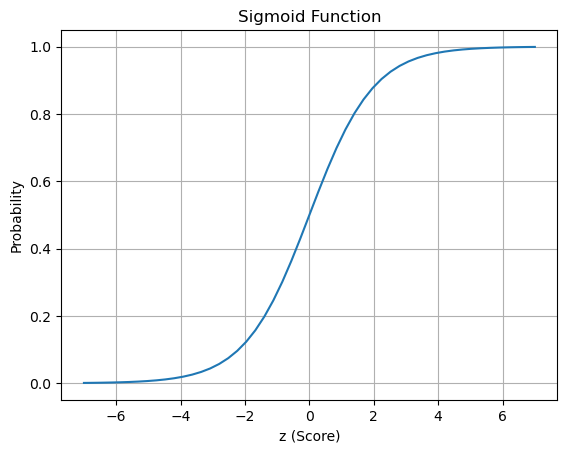

In [ ]:
# Sigmoid function-এর গ্রাফ প্লট করা
z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))
plt.title("Sigmoid Function")
plt.xlabel("z (Score)")
plt.ylabel("Probability")
plt.grid(True)
plt.show()

## Linear এবং Logistic Regression-এর কোড ইমপ্লিমেন্টেশন

নিচে Linear regression এবং Logistic regression-এর বেসিক কোড দেওয়া হলো। পার্থক্যটা খুব সামান্য: Logistic regression-এর ক্ষেত্রে আমরা লুপের মাধ্যমে পাওয়া score-কে রিটার্ন করার ঠিক আগে `sigmoid()` ফাংশনের ভেতর পাস করি।

In [ ]:
# Linear Regression
def linear_regression(xi, w0, w):
    result = w0
    for j in range(len(w)):
        result = result + xi[j] * w[j]
    return result

# Logistic Regression
def logistic_regression(xi, w0, w):
    score = w0
    for j in range(len(w)):
        score = score + xi[j] * w[j]
    # শুধুমাত্র এই অংশটুকু Linear regression থেকে আলাদা
    result = sigmoid(score)
    return result

# 3.10 Training logistic regression with Scikit-Learn

এই লেসনে আমরা Scikit-Learn লাইব্রেরি ব্যবহার করে **Logistic Regression** মডেল ট্রেইন করব। তারপর মডেলটি validation ডেটাসেটের উপর অ্যাপ্লাই করে দেখব আমাদের প্রেডিকশন কতটা সঠিক (Accuracy)।

### কিছু গুরুত্বপূর্ণ Technical Terms (শব্দার্থ):
* **Scikit-Learn:** পাইথনের একটি খুব জনপ্রিয় মেশিন লার্নিং লাইব্রেরি।
* **Training a model:** মডেলকে ডেটা দিয়ে শেখানো, যাতে সে ডেটার প্যাটার্ন বুঝতে পারে।
* **Accuracy:** আমাদের মডেলের প্রেডিকশনগুলোর মধ্যে কত শতাংশ সঠিক হয়েছে তার পরিমাপ।
* **Hard Predictions:** যখন মডেল সরাসরি সিদ্ধান্ত দিয়ে দেয় (যেমন: 0 বা 1)।
* **Soft Predictions:** যখন মডেল সম্ভাবনা বা probability দেয় (যেমন: Churn হওয়ার সম্ভাবনা 70%)।

## Training the model

Scikit-Learn-এ Logistic Regression আগে থেকেই ইমপ্লিমেন্ট করা আছে। আগের মডিউলে আমরা যেভাবে `LinearRegression` মডেল ট্রেইন করেছিলাম, ঠিক একই প্যাটার্নে আমরা মডেল তৈরি করে `fit()` ফাংশন কল করব।

* **`solver='lbfgs'`:** এটি একটি অপটিমাইজেশন অ্যালগরিদম যা সবচেয়ে ভালো weights ($w$) খুঁজে বের করতে সাহায্য করে।

In [16]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='lbfgs') # by default solver = 'lbgs' thake
model.fit(X_train, y_train)

NameError: name 'X_train' is not defined

মডেল `fit` হওয়ার পর, এটি bias ($w_0$) এবং weights ($w$) শিখে ফেলে।

* **`model.intercept_[0]`:** এটি আমাদের Bias ($w_0$) রিটার্ন করে।
* **`model.coef_[0]`:** এটি আমাদের মডেলের Weights ($w$) গুলো রিটার্ন করে।

In [ ]:
print("Bias:", model.intercept_[0])

In [ ]:
print("Weights:", model.coef_[0].round(3))

## Making predictions

Scikit-Learn-এর এই মডেলে প্রেডিকশন করার দুটি মেথড আছে:
1. **`model.predict(X)`:** এটি Hard predictions দেয়, অর্থাৎ সরাসরি 0 বা 1 উত্তর দেবে।
2. **`model.predict_proba(X)`:** এটি Soft predictions দেয়, অর্থাৎ 0 বা 1 হওয়ার probability জানাবে।

আমরা probability চাই, কারণ আমরা নিজেদের ইচ্ছেমতো threshold সেট করব (যেমন, 50% বা তার বেশি সম্ভাবনা থাকলে আমরা বলব কাস্টমার Churn করবে)।

`predict_proba()` দুটি কলামের একটি ম্যাট্রিক্স রিটার্ন করে। প্রথমটি class 0-এর probability, আর দ্বিতীয়টি class 1 (Churn)-এর probability। আমরা শুধু দ্বিতীয় কলামটি `[:, 1]` নিব।

In [ ]:
# Validation set-এর উপর probability বের করা
y_pred = model.predict_proba(X_val)[:, 1]

In [ ]:
# যদি Churn হওয়ার সম্ভাবনা 50% বা তার বেশি হয়, তবে True, না হলে False
churn_decision = (y_pred >= 0.5)

## Accuracy (মডেল কতটা সঠিক?)

আমাদের প্রেডিকশন কতটা সঠিক হয়েছে, তা দেখার জন্য আমরা আমাদের প্রেডিক্ট করা `churn_decision`-এর সাথে validation set-এর আসল ডেটা `y_val` তুলনা করব।

In [ ]:
# Accuracy বের করা
(y_val == churn_decision).mean()

আমরা চাইলে একটি DataFrame বানিয়ে প্রেডিকশন এবং আসল ভ্যালু পাশাপাশি রেখে চেক করতে পারি।

In [ ]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = churn_decision.astype(int)
df_pred['actual'] = y_val

# যেখানে prediction এবং actual ভ্যালু মিলে গেছে, সেখানে True বসবে
df_pred['correct'] = df_pred.prediction == df_pred.actual

print("Accuracy:", df_pred.correct.mean())

# 3.11 Model Interpretation

এই লেসনে আমরা দেখব যে মডেলটি ট্রেইন করার পর ভেতরে আসলে কী ঘটেছে। আমরা মডেলের বের করা weight-গুলোর সাথে প্রতিটি ফিচারের নাম মিলিয়ে দেখব। এরপর একটি ছোট মডেল তৈরি করে বোঝার চেষ্টা করব যে এই weight-গুলো কীভাবে কাজ করে।

### কিছু গুরুত্বপূর্ণ Technical Terms (শব্দার্থ):
* **Model Interpretation:** মডেলটি কীভাবে কাজ করছে বা কোনো সিদ্ধান্ত নিচ্ছে তা বিশ্লেষণ করা।
* **Coefficients ($w$):** প্রতিটি ফিচারের গুরুত্ব (weight)।
* **Bias ($w_0$):** বেসলাইন প্রেডিকশন।
* **One-hot Encoding:** ক্যাটাগরিক্যাল ডেটাকে (যেমন- Contract: Month-to-month, One year, Two year) 0 এবং 1 দিয়ে সাজানো।
* **`zip()`:** পাইথনের একটি ফাংশন যা দুটি লিস্টকে জোড়া লাগাতে সাহায্য করে।

## Looking at the coefficients

আগের লেসনে আমাদের মডেলে 45টি weight ছিল, কিন্তু সেগুলো শুধু একটা নাম্বারের লিস্ট বা array আকারে ছিল। আমরা বুঝতে পারছিলাম না কোন ফিচারের জন্য কোন weight-টা দেওয়া হয়েছে।

তাই আমরা `zip()` ফাংশন ব্যবহার করে প্রতিটি ফিচারের নামের সাথে তার weight-কে যুক্ত করে নেব।

In [ ]:
# zip() ফাংশন কীভাবে কাজ করে তার একটি উদাহরণ
a = [1, 2, 3, 4]
b = 'abcd'
dict(zip(a, b))

একইভাবে, আমরা আমাদের ডেটাসেটের ফিচারের নামের সাথে তাদের respective weight যুক্ত করতে পারি:

In [ ]:
# ফিচারের নাম এবং weight একসাথে করে একটি dictionary বানানো
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

Weight দেখে আমরা যা বুঝতে পারি:
* **Positive Weight:** কোনো ফিচারের weight পজিটিভ হলে তা Churn হওয়ার সম্ভাবনা (probability) বাড়িয়ে দেয়।
* **Negative Weight:** কোনো ফিচারের weight নেগেটিভ হলে তা Churn হওয়ার সম্ভাবনা কমিয়ে দেয়।

যেমন, যাদের Contract `month-to-month` তাদের weight পজিটিভ (0.475), মানে তারা চলে যাওয়ার সম্ভাবনা বেশি। আর যাদের Contract `two_year` তাদের weight নেগেটিভ (-0.408), মানে তাদের চলে যাওয়ার সম্ভাবনা অনেক কম।

45টি ফিচারের সবগুলো একসাথে বোঝা কঠিন, তাই আমরা শুধু গুরুত্বপূর্ণ ৩টি ফিচার নিয়ে একটি ছোট মডেল তৈরি করব।

## A smaller model

আমরা শুধুমাত্র `contract`, `tenure`, এবং `monthlycharges` ফিচারগুলো নেব।

In [ ]:
small = ['contract', 'tenure', 'monthlycharges']

dicts_train_small = df_train[small].to_dict(orient='records')
dicts_val_small = df_val[small].to_dict(orient='records')

# নতুন DictVectorizer তৈরি করা
dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

# নতুন ফিচারের নাম দেখা (মোট ৫টি কলাম হবে)
dv_small.get_feature_names_out()

এবার এই ছোট ডেটা ব্যবহার করে মডেল ট্রেইন করা যাক:

In [ ]:
X_train_small = dv_small.transform(dicts_train_small)

model_small = LogisticRegression(solver='lbfgs')
model_small.fit(X_train_small, y_train)

# Bias ($w_0$) বের করা
w0 = model_small.intercept_[0]
print("Bias:", w0)

# Weights বের করা
w = model_small.coef_[0]
dict(zip(dv_small.get_feature_names_out(), w.round(3)))

এখান থেকে আমরা খুব পরিষ্কারভাবে বুঝতে পারি:
* `contract=two_year` (-0.949) এর তুলনায় `contract=month-to-month` (0.97) Churn হওয়ার সম্ভাবনা অনেক বাড়িয়ে দেয়।
* `tenure` (-0.036): কাস্টমার যত বেশি মাস থাকবে, তার Churn হওয়ার সম্ভাবনা তত কমবে।
* `monthlycharges` (0.027): বিল যত বাড়বে, Churn হওয়ার সম্ভাবনা কিছুটা বাড়বে।

## Scoring a customer by hand

আমরা মডেলের ৫টি মান ব্যবহার করে ম্যানুয়ালি কোনো কাস্টমারের score বের করতে পারি।
ধরো, একজন কাস্টমারের `two-year` কনট্র্যাক্ট, মাসে $30 বিল দেয়, এবং ২৪ মাস (tenure) ধরে আছে।

যেহেতু তার কনট্র্যাক্ট `two-year`, তাই শুধুমাত্র `contract=two_year` এর weight 1 দিয়ে গুণ হবে, বাকিগুলো 0 হয়ে যাবে।

In [ ]:
# ম্যানুয়ালি Score হিসেব করা
score = -2.47 + (-0.949) + 30 * 0.027 + 24 * (-0.036)
print("Score:", score)

এবার এই Score-কে Probability-তে রূপান্তর করার জন্য `sigmoid()` ফাংশন ব্যবহার করতে হবে।

In [ ]:
# Jupyter-এ '_' আগের সেলের রেজাল্ট বোঝায়।
# আমরা সরাসরি score ভেরিয়েবলটি পাস করছি।
sigmoid(score)

আউটপুট হবে প্রায় 3% (0.03)। এর মানে হলো, এই লয়্যাল কাস্টমারের সার্ভিস ছেড়ে যাওয়ার সম্ভাবনা খুবই কম, যা আমরা আশা করেছিলাম।

**মনে রাখার মতো বিষয়:**
* Sigmoid(0) = 0.5।
* অর্থাৎ, Score পজিটিভ হলে Probability 50% এর বেশি হবে (Churn হওয়ার সম্ভাবনা বেশি)।
* আর Score নেগেটিভ হলে Probability 50% এর কম হবে (Churn হওয়ার সম্ভাবনা কম)।